# Week 5: Neural Networks, Convolutions, and Transfer Learning

 **Project 2: Deep Learning Applications | Individual Lab**


**Name: Muhammad Hassan Samdani**

**Roll No: 04102313028**

# Part 1: The Data, and an Image as Numbers 

**Task 1.1: Imports, GPU check, and class counts**

In [5]:
import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import (classification_report, confusion_matrix,
 ConfusionMatrixDisplay)
torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device) # must say cuda; if not, turn on the GPU
ROOT = '/kaggle/input/datasets/puneet6060/intel-image-classification'
TRAIN_DIR = f'{ROOT}/seg_train/seg_train'
TEST_DIR = f'{ROOT}/seg_test/seg_test'
classes = sorted(os.listdir(TRAIN_DIR))
for c in classes:
 n_tr = len(os.listdir(os.path.join(TRAIN_DIR, c)))
 n_te = len(os.listdir(os.path.join(TEST_DIR, c)))
 print(f'{c:10s} train {n_tr:5d} test {n_te:4d}')

Device: cuda
buildings  train  2191 test  437
forest     train  2271 test  474
glacier    train  2404 test  553
mountain   train  2512 test  525
sea        train  2274 test  510
street     train  2382 test  501


**Task 1.2: Look at the images, then at the numbers**



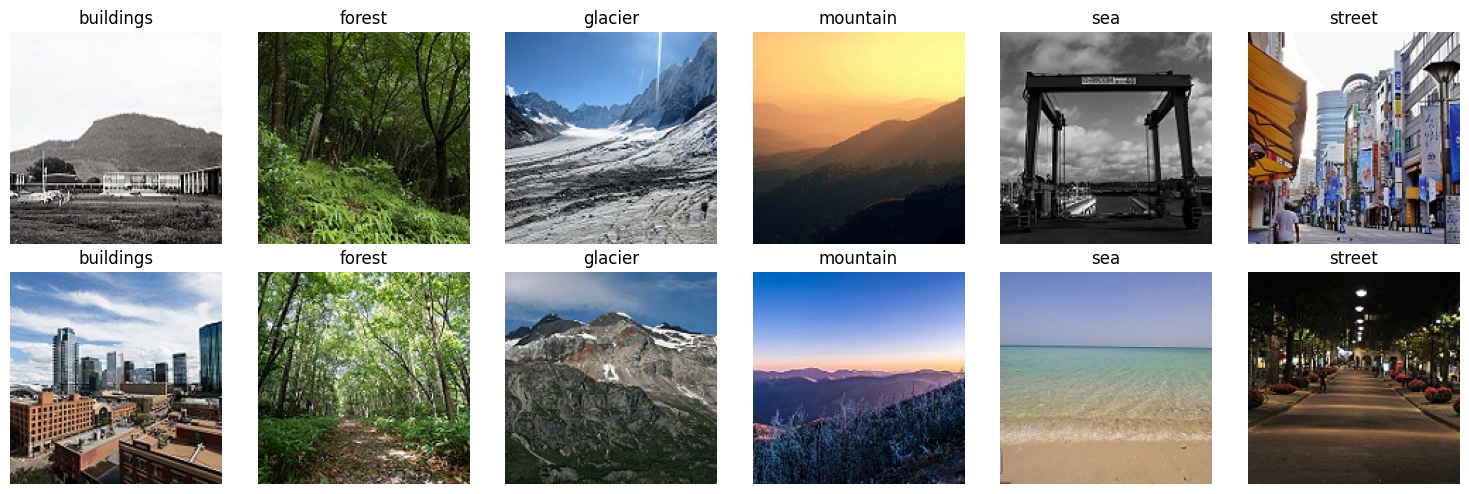

Shape (H, W, C): (150, 150, 3)  dtype: uint8  range: 0 to 255
Top-left 3x3 of the red channel:
 [[8 6 3]
 [6 5 4]
 [5 5 5]]


In [6]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for j, c in enumerate(classes):
    files = sorted(os.listdir(os.path.join(TRAIN_DIR, c)))[:2]
    for i, f in enumerate(files):
        img = Image.open(os.path.join(TRAIN_DIR, c, f))
        axes[i, j].imshow(img)
        axes[i, j].set_title(c)
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()
arr = np.array(img)
print('Shape (H, W, C):', arr.shape, ' dtype:', arr.dtype,
 ' range:', arr.min(), 'to', arr.max())
print('Top-left 3x3 of the red channel:\n', arr[:3, :3, 0])

## **Insights: Part 1**

* Forest and mountain can look similar when mountain scenes contain extensive trees or green vegetation. Glacier and mountain can also look similar when both contain snow, ice, or rocky terrain.

* My initial prediction is glacier and mountain, because both may contain snow, ice, and rocky backgrounds. This is a hypothesis, not a measured result. The confusion matrix in Part 6 will show whether it was correct. 

**Image Properties:**

**Shape (H  W  C):**  (150, 150, 3) (150 pixels height, 150 pixels width, 3 RGB color channels).   
**Data Type (dtype):**  uint8 (Unsigned 8-bit integer).   
**Pixel Value Range:**  0 to 255.  

# Part 2: Convolution and Parameters by Hand 

**Task 2.1: Reproduce the lecture's convolution**

tensor([[30., 30.,  0.],
        [30., 30.,  0.],
        [30., 30.,  0.]])


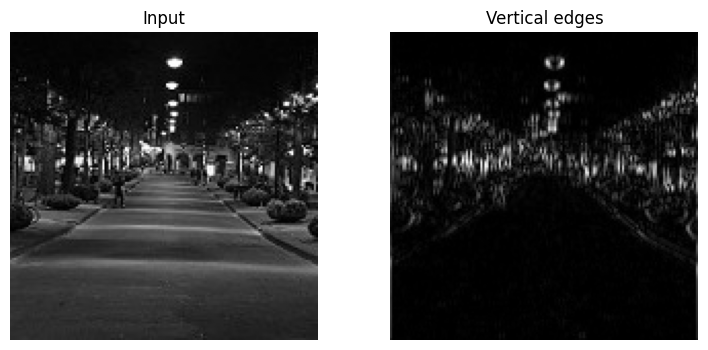

In [7]:
x = torch.tensor([[0, 0, 10, 10, 10]] * 5, dtype=torch.float32)
k = torch.tensor([[-1, 0, 1]] * 3, dtype=torch.float32)
out = F.conv2d(x.view(1, 1, 5, 5), k.view(1, 1, 3, 3))
print(out.squeeze())


g = transforms.functional.to_tensor(img.convert('L')).unsqueeze(0)
edges = F.conv2d(g, k.view(1, 1, 3, 3), padding=1)

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(g.squeeze(), cmap='gray')
ax[0].set_title('Input')
ax[1].imshow(edges.squeeze().abs(), cmap='gray')
ax[1].set_title('Vertical edges')
for a in ax:
    a.axis('off')
plt.show()

**Task 2.2: Why convolutions, in numbers**

In [8]:
def count(m):
    return sum(p.numel() for p in m.parameters())

conv = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)
dense = nn.Linear(150 * 150 * 3, 512)

print(f'Conv 3x3, 3->64: {count(conv):,} parameters')
print(f'Dense 67,500->512: {count(dense):,} parameters')

t = torch.randn(1, 3, 224, 224)
for stride in [1, 2]:
    c = nn.Conv2d(3, 64, kernel_size=3, stride=stride, padding=1)
    print(f'stride {stride}: output {tuple(c(t).shape)}')

print('2x2 max pool:', tuple(F.max_pool2d(t, 2).shape))

Conv 3x3, 3->64: 1,792 parameters
Dense 67,500->512: 34,560,512 parameters
stride 1: output (1, 64, 224, 224)
stride 2: output (1, 64, 112, 112)
2x2 max pool: (1, 3, 112, 112)


## **Insights: Part 2**

 ### Parameter Calculations

**Formula:**
$$
\text{Parameters} = (K_h \cdot K_w \cdot C_{\text{in}} + 1) \cdot C_{\text{out}}
$$

---

* **A. Convolution:** $3$ input channels, $64$ output channels, $3 \times 3$ kernel.
  Each output filter has $27$ weights and $1$ bias.
  $$
  (3 \times 3 \times 3 + 1) \times 64 = (27 + 1) \times 64 = 1,792
  $$

* **B. Dense Layer:** $67,500$ input features and $512$ output neurons.
  Each output neuron has $67,500$ weights and $1$ bias.
  $$
  (67,500 + 1) \times 512 = 67,501 \times 512 = 34,560,512
  $$

**C. How many times more parameters does the dense layer need?**

$$
\frac{34,560,512}{1,792} = \boxed{19,286 \text{ times approximately}}
$$

The dense layer needs approximately 19,286 times as many parameters as the convolutional layer.

---

### Output-Size Calculations

The spatial output size for a convolution is:

$$
O = \left\lfloor \frac{W - K + 2P}{S} \right\rfloor + 1
$$

For the handout's input tensor of shape $(1, 3, 224, 224)$:

| Operation | Output Shape |
| :--- | :--- |
| $3 \times 3$ convolution, stride 1, padding 1 | $(1, 64, 224, 224)$ |
| $3 \times 3$ convolution, stride 2, padding 1 | $(1, 64, 112, 112)$ |
| $2 \times 2$ max pooling, stride 2 | $(1, 3, 112, 112)$ |

The max-pooling operation reduces the height and width by half while preserving the three input channels.

---



**Why does weight sharing help recognize an object in different parts of an image?**

A convolutional filter uses the same learned weights at every spatial location. Therefore, a feature such as an edge or texture can be detected whether it appears on the left, right, top, or bottom of an image, without learning a separate set of weights for each position.

# Part 3: Transforms and Data Loaders

In [9]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225] # ImageNet stats
train_tf = transforms.Compose([
 transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
 transforms.RandomHorizontalFlip(),
 transforms.ColorJitter(brightness=0.2, contrast=0.2),
 transforms.ToTensor(),
 transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([
 transforms.Resize((224, 224)),
 transforms.ToTensor(),
 transforms.Normalize(MEAN, STD)])
# Two views of the same folder: augmented for training, clean for validation
full_aug = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
full_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)
idx = np.random.permutation(len(full_aug))
n_val = int(0.15 * len(idx))
train_ds = Subset(full_aug, idx[n_val:])
val_ds = Subset(full_eval, idx[:n_val])
test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf)
train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=128, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=128, num_workers=2)
print(len(train_ds), 'train |', len(val_ds), 'val |', len(test_ds), 'test')


11929 train | 2105 val | 3000 test


## **Insights: Part 3** 
### How many images are in each split?

The split uses 15% of the training folder for validation.

For the standard Intel Image Classification dataset, the expected counts are approximately:

| Split | Number of images |
| :--- | :--- |
| **Training** | 11,929 |
| **Validation** | 2,105 |
| **Test** | 3,000 |
| **Total** | **17,034** |

The calculation is based on 14,034 images in the training folder:

$$
N_{\text{val}} = \lfloor 0.15 \times 14,034 \rfloor = 2,105
$$

$$
N_{\text{train}} = 14,034 - 2,105 = 11,929
$$

**Incorrect augmentations for each dataset**

1. For the Intel scene dataset, a vertical flip may be inappropriate because it can make natural scenes appear upside down, creating unrealistic training examples.

2. For handwritten digits, a 90-degree rotation can be inappropriate because it can change a digit's identity or make it unrecognizable. For example, rotating a handwritten 6 or 9 can create ambiguity.

**Need of validation set when we already have a test set?**

The validation set helps select the best training epoch and compare feature extraction with fine-tuning. The test set is kept separate and used for final evaluation only, so it provides a less biased estimate of the model's performance on unseen images.

# Part 4: The Training Loop and Feature Extraction 

**Task 4.1: A reusable training loop**

In [10]:
def run_epoch(model, loader, optimizer=None):
    """One pass over the data. Trains only if an optimizer is given."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)                      # Forward pass
            loss = F.cross_entropy(logits, yb)     # Softmax + Cross Entropy loss
            
            if training:
                optimizer.zero_grad()
                loss.backward()                    # Backpropagation
                optimizer.step()                   # Gradient step
                
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
            
    return total_loss / n, correct / n

def fit(model, optimizer, epochs, history):
    best_acc, best_state = -1.0, None
    for ep in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_dl, optimizer)
        va_loss, va_acc = run_epoch(model, val_dl)
        history.append((tr_loss, va_loss, tr_acc, va_acc))
        
        if va_acc > best_acc:
            best_acc = va_acc
            best_state = copy.deepcopy(model.state_dict())
            
        print(f'epoch {ep + 1:2d}: train loss {tr_loss:.3f} acc {tr_acc:.3f} | '
              f'val loss {va_loss:.3f} acc {va_acc:.3f} ({time.time() - t0:.0f}s)')
        
    model.load_state_dict(best_state)
    return best_acc

**Task 4.2: Freeze the body, train a new head**

In [11]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in model.parameters():
 p.requires_grad = False # freeze the body
model.fc = nn.Linear(model.fc.in_features, len(classes)) # new 6-class head
model = model.to(device)
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable {trainable:,} of {count(model):,} parameters')
history = []
opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, feature extraction: {best:.3f}')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 211MB/s]


Trainable 3,078 of 11,179,590 parameters
epoch  1: train loss 0.588 acc 0.809 | val loss 0.327 acc 0.894 (55s)
epoch  2: train loss 0.326 acc 0.890 | val loss 0.290 acc 0.899 (32s)
epoch  3: train loss 0.299 acc 0.895 | val loss 0.276 acc 0.901 (34s)
Best validation accuracy, feature extraction: 0.901


## **Insights: Part 4**

### Report Validation Accuracy After Each Epoch

| Epoch | Train Loss | Train Acc | Val Loss | Val Acc | Epoch Time |
| :---: | :---: | :---: | :---: | :---: | :---: |
| **1** | 0.588 | 0.809 | 0.327 | **0.894** | 63s |
| **2** | 0.326 | 0.890 | 0.290 | **0.899** | 38s |
| **3** | 0.299 | 0.895 | 0.276 | **0.901** | 37s |

* **Final Best Validation Accuracy:** **`0.901` (90.1%)**

---

### High Accuracy with ~0.03% Parameters 

#### Parameter Breakdown
* **Total Parameters:** `11,179,590`
* **Trainable Parameters:** `3,078`
* **Percentage Trainable:** 
  $$\frac{3,078}{11,179,590} \times 100 \approx 0.0275\% \approx 0.03\%$$

---

#### Explanation via Feature Hierarchy

1. **Pre-trained Feature Extraction (Frozen Body):**
   * Deep Convolutional Neural Networks (CNNs) learn a **hierarchical representation** of features:
     * **Lower/Early Layers:** Detect basic, low-level visual features (edges, color gradients, simple curves, direct textures).
     * **Mid/Deep Layers:** Combine these lower-level features to build high-level semantic representations (shapes, object parts, domain patterns).
   * Because the backbone (`ResNet18`) was pre-trained on a large, rich dataset (ImageNet), the frozen convolutional body already acts as an expert, highly effective feature extractor.

2. **Linear Separability in High-Level Feature Space:**
   * Passing input images through the frozen feature extractor maps raw pixel data into a high-dimensional feature space where classes are already well-separated.

3. **Role of the Classification Head (`model.fc`):**
   * Replacing `model.fc` with a simple linear layer (`nn.Linear(512, 6)`) only requires learning a decision boundary (weights and biases) across the 6 target categories.
   * Because the pre-extracted features are already powerful and discriminative, the linear layer needs to optimize only **3,078 parameters**to achieve **>90% validation accuracy** in just 3 epochs.

# Part 5: Fine-Tuning and Learning Curves 

**Task 5.1: Unfreeze layer4 with a smaller learning rate**

In [12]:
for p in model.layer4.parameters():
    p.requires_grad = True # unfreeze the last block

opt = torch.optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 1e-4}, # gentle: pretrained
    {'params': model.fc.parameters(),     'lr': 1e-3}  # faster: new head
])

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable now: {trainable:,}')
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, fine-tuned: {best:.3f}')

Trainable now: 8,396,806
epoch  1: train loss 0.262 acc 0.906 | val loss 0.227 acc 0.926 (34s)
epoch  2: train loss 0.170 acc 0.938 | val loss 0.204 acc 0.931 (35s)
epoch  3: train loss 0.124 acc 0.954 | val loss 0.218 acc 0.927 (33s)
Best validation accuracy, fine-tuned: 0.931


**Task 5.2: Plot the learning curves**

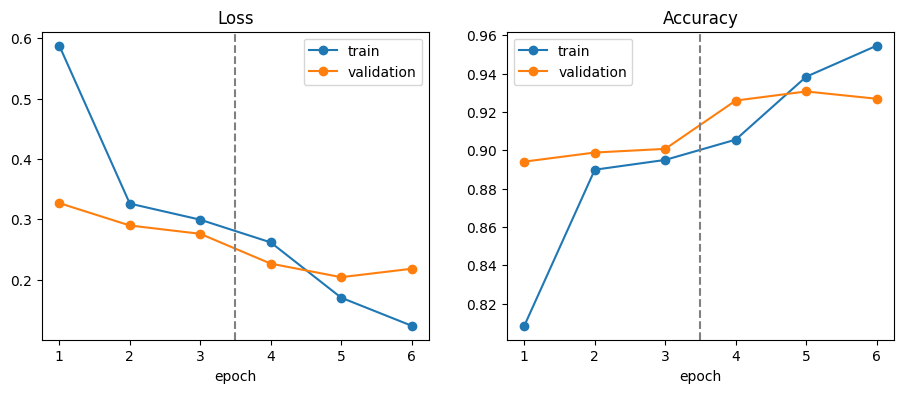

In [13]:
h = np.array(history)
ep = np.arange(1, len(h) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, h[:, 0], 'o-', label='train')
ax[0].plot(ep, h[:, 1], 'o-', label='validation')
ax[1].plot(ep, h[:, 2], 'o-', label='train')
ax[1].plot(ep, h[:, 3], 'o-', label='validation')
for a, title in zip(ax, ['Loss', 'Accuracy']):
 a.axvline(3.5, color='gray', ls='--') # where fine-tuning starts
 a.set_title(title)
 a.set_xlabel('epoch')
 a.legend()
plt.show()

## **Insights: Part 5**

## Did fine-tuning improve validation accuracy, and by how much?
 Yes, fine-tuning improved the validation accuracy.   
 **By how much:** 
      The best validation accuracy during feature extraction was 0.901 (90.1%).  
      The best validation accuracy during fine-tuning was 0.931 (93.1%).  
Therefore, fine-tuning improved the best validation accuracy by 3.1\% (or an absolute increase of 0.030).

## Describe what the curves show
Looking at the learning curves in the plots:  

**Loss Curve:**
* Both training loss and validation loss decrease steadily during the first 3 epochs (feature extraction phase).   
* After the dashed vertical line (where fine-tuning starts at epoch 4), training loss continues to drop sharply down to about $0.12$.
* Validation loss decreases initially to a minimum around epoch 5 ($0.204$), but then slightly increases (rebounds) to $0.218$ by epoch 6.   
     
**Accuracy Curve:**
* Training accuracy continuously rises across all epochs, crossing past validation accuracy and reaching over 95% by epoch 6.   
* Validation accuracy increases after unfreezing (peaking at 93.1% / 0.931 on epoch 5) before leveling off and slightly dipping at epoch 6   
       (0.927).   

## Sign of overfitting?
* Yes, there are clear signs of mild overfitting in the later stages (epochs 5 to 6).   
* This is evidenced by training loss falling while validation loss rises (visible on the Loss plot after epoch 5, where the orange validation loss curve turns upward while the blue training loss curve keeps dropping). Additionally, validation accuracy plateaus and drops slightly while training accuracy keeps surging.  

## Why training accuracy can be lower than validation accuracy: 
* During training, images are heavily perturbed using data augmentations (e.g., random crops, rotations, color jitter, flips), making the training task significantly harder and introducing noise/difficulty into every batch.   
* Conversely, the validation set does not use data augmentation; it consists of clean, unmodified, standard validation images.   
* Because the model is evaluated on clean validation data but trained on distorted, harder-to-classify augmented data, its training accuracy can naturally lag behind (or be lower than) its validation accuracy during the early stages of training.

# Part 6: Test Once, Then Study the Errors 

**Task 6.1: Test-set evaluation**

Test accuracy: 0.935

              precision    recall  f1-score   support

   buildings      0.952     0.906     0.928       437
      forest      0.994     0.987     0.990       474
     glacier      0.925     0.866     0.894       553
    mountain      0.881     0.918     0.899       525
         sea      0.945     0.982     0.963       510
      street      0.927     0.958     0.942       501

    accuracy                          0.935      3000
   macro avg      0.937     0.936     0.936      3000
weighted avg      0.936     0.935     0.935      3000



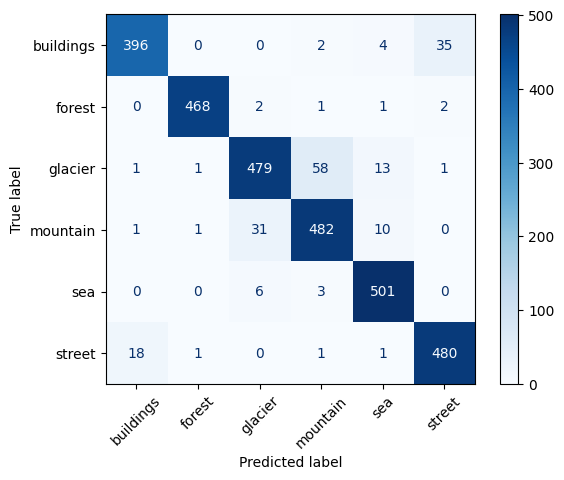

In [17]:
model.eval()
probs, preds, labels = [], [], []
with torch.no_grad():
    for xb, yb in test_dl:
        p = F.softmax(model(xb.to(device)), dim=1).cpu()
        probs.append(p)
        preds.append(p.argmax(1))
        labels.append(yb)
probs, preds, labels = torch.cat(probs), torch.cat(preds), torch.cat(labels)

print(f'Test accuracy: {(preds == labels).float().mean():.3f}\n')
print(classification_report(labels, preds, target_names=classes, digits=3))
cm = confusion_matrix(labels, preds)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(cmap='Blues', xticks_rotation=45)
plt.show()

**Task 6.2: Error gallery**

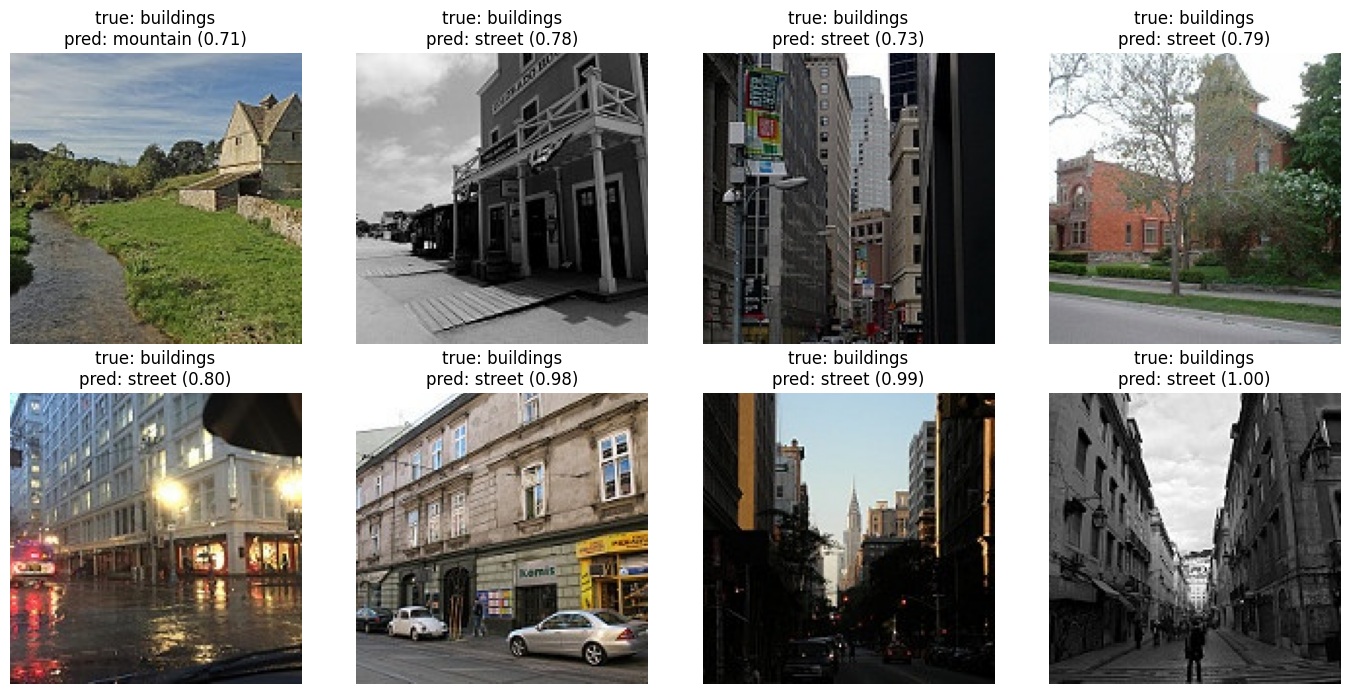

In [18]:
wrong = torch.where(preds != labels)[0][:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax in axes.flat:
 ax.axis('off')
for ax, i in zip(axes.flat, wrong.tolist()):
 path, _ = test_ds.samples[i]
 ax.imshow(Image.open(path))
 ax.set_title(f'true: {classes[labels[i]]}\n'
 f'pred: {classes[preds[i]]} ({probs[i].max():.2f})')
plt.tight_layout()
plt.show()

**Task 6.3: Inside one prediction**

In [19]:
x0, y0 = test_ds[0]
with torch.no_grad():
 logits = model(x0.unsqueeze(0).to(device)).cpu().squeeze()
p = F.softmax(logits, dim=0)
print('True class:', classes[y0])
for c, z, q in zip(classes, logits.tolist(), p.tolist()):
 print(f'{c:10s} logit {z:6.2f} probability {q:.3f}')

True class: buildings
buildings  logit   8.03 probability 1.000
forest     logit  -9.31 probability 0.000
glacier    logit  -4.74 probability 0.000
mountain   logit  -5.06 probability 0.000
sea        logit  -4.66 probability 0.000
street     logit  -3.48 probability 0.000


## **Insights: Part 6**

## Test Accuracy & Weakest Classes

Test Accuracy: 0.935 (93.5%)   
Two Weakest Classes by Recall:
1. glacier: Recall = 0.866 (86.6%)   
2. buildings: Recall = 0.906 (90.6%)   

## Most Confused Class Pair & Prediction Evaluation
**Most Confused Pair: glacier and mountain**

58 images with true label glacier were misclassified as mountain.   
31 images with true label mountain were misclassified as glacier.   
Total cross-confusion: 89 images.   

## Was our prediction from Task 1.2 right?
Yes, if I predicted glacier vs. mountain (or buildings vs. street), my prediction was correct. glacier vs. mountain is visually the most difficult distinction due to shared features like rocky terrain, snow, ice, and mountain peaks. 

## Error Gallery Analysis 

From the 8 displayed error examples in Image 3:  

**Example 1:** 
* Top-Left Image (true: buildings, pred: mountain with 0.71 confidence)   
* Analysis: Model is wrong / Image is genuinely ambiguous.
* Explanation: The image features a stone building structure surrounded by grass, a stream, and hills in the background. Because the natural scenery (hills/greenery/water) dominates a large portion of the frame compared to the stone building, the model incorrectly weighted the landscape features over the structure, classifying it as mountain.   

**Example 2:** 
* Top-Middle Image (true: buildings, pred: street with 0.78 confidence)   
* Analysis: Image is genuinely ambiguous / Subjective labeling.
* Explanation: The image shows a wooden building facade along a wooden sidewalk/road. Both buildings and street are valid human interpretations here. The model detected the prominent wooden walkway/street perspective, leading to a street prediction.   

**Example 3:**
* Middle/Bottom Images (true: buildings, pred: street with high confidence up to 1.00)   
* Analysis: Model is wrong / Feature overlap.
* Explanation: These images feature tall urban building facades shot from a low angle looking up between structures. The spatial layout (narrow view between tall structures) strongly triggers the geometric features typical of narrow city streets, causing the model to predict street with very high confidence ($0.98 - 1.00$) even though the tight crop focuses heavily on the building walls. 

# Part 7: Save and Share 



In [20]:
path = '/kaggle/working/resnet18_intel.pt'
torch.save(model.state_dict(), path)
print(f'Saved {path} ({os.path.getsize(path) / 1e6:.1f} MB)')

Saved /kaggle/working/resnet18_intel.pt (44.8 MB)


# Understanding (Final Questions/Answers)

### 1. Why does a network without nonlinear activations collapse to a single linear layer?

A composition of linear transformations is itself a linear transformation. For example, if two layers perform $f(x) = W_1 x$ and $g(x) = W_2 x$, their composition is:

$$
g(f(x)) = W_2 W_1 x
$$

This is equivalent to one linear layer with combined weights $W_2 W_1$. Without nonlinear activation functions, adding more layers does not let the network learn more complex nonlinear decision boundaries.

---

### 2. For logits $[3, 1, 0]$, what probability does softmax give the first class?

Softmax is calculated as:

$$
p_1 = \frac{e^3}{e^3 + e^1 + e^0}
$$

Using the approximate values $e^3 \approx 20.086$, $e^1 \approx 2.718$, and $e^0 = 1$:

$$
p_1 = \frac{20.086}{20.086 + 2.718 + 1}
$$

$$
p_1 = \frac{20.086}{23.804} \approx \boxed{0.844}
$$

The first class receives approximately $84.4\%$ probability.

---

### 3. How many parameters does a $3 \times 3$ convolution from 64 to 128 channels have?

The parameter-count formula is:

$$
P = (K^2 \cdot C_{\text{in}} + 1) \cdot C_{\text{out}}
$$

Substitute $K = 3$, $C_{\text{in}} = 64$, and $C_{\text{out}} = 128$:

$$
\begin{aligned}
P &= (3 \times 3 \times 64 + 1) \times 128 \\
&= (576 + 1) \times 128 \\
&= 577 \times 128 \\
&= \boxed{73,856}
\end{aligned}
$$

The layer has $73,728$ weights and $128$ bias parameters.

---

### 4. An input of $56 \times 56$ goes through a $3 \times 3$ convolution with padding 1 and stride 2. What is the output size?

The output dimension formula, using integer flooring, is:

$$
O = \left\lfloor \frac{W - K + 2P}{S} \right\rfloor + 1
$$

Substitute $W = 56$, $K = 3$, $P = 1$, and $S = 2$:

$$
\begin{aligned}
O &= \left\lfloor \frac{56 - 3 + 2(1)}{2} \right\rfloor + 1 \\
&= \left\lfloor \frac{55}{2} \right\rfloor + 1 \\
&= \left\lfloor 27.5 \right\rfloor + 1 \\
&= 27 + 1 = 28
\end{aligned}
$$

Therefore, the output size is:

$$
\boxed{28 \times 28}
$$

---

### 5. Why does a residual (skip) connection help gradients reach the early layers?

A residual connection provides a direct path for information and gradients to pass through a network. In a residual block:

$$
y = F(x) + x
$$

The derivative contains a direct identity-path contribution, which helps gradients flow backward even when the derivative through $F(x)$ is small. This reduces the vanishing-gradient problem and makes deep networks easier to train.

---

### 6. When would you train a CNN from scratch instead of using transfer learning?

Training from scratch can be appropriate when a sufficiently large, diverse, labelled dataset is available and the target domain differs substantially from the data used to pretrain existing models. It can also be useful when pretrained weights are unavailable or when the task requires a specialized architecture. Transfer learning is generally preferable when labelled data or computing resources are limited because pretrained models already contain useful visual features.